# Hyperparameter Tuning on Log Loss for Calibrated Predictions in Classification

In [ ]:
import datetime
import os
from joblib import cpu_count, Parallel, delayed, parallel_config
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import pipeline as sklearn_pipeline
from sklearn.metrics import auc, make_scorer, precision_recall_curve, brier_score_loss, balanced_accuracy_score
from sklearn.model_selection import StratifiedGroupKFold

from mother import feature_generation as fg
from mother.cv.core import HdbscanGroupingFromMols, TanimotoGroupingFromMols
from mother.ml.models.m_lasso import LassoClassifierBinaryMother
from mother.optimization import MotherTuner
from mother.pipeline_utils import mother_cv
from mother.preprocessing import SmilesToMolTransformer, StandardizerTransformer

## A) Check if previous results exist

In [155]:
if Path("05_results").exists() and len(list(Path("05_results").glob("*.pkl"))) > 0:
    tune_again = False
    print(f"Results exist. Suggest skipping steps until E). `tune_again` set to {tune_again}.")
else:
    tune_again = True
    print(f"No results found. `tune_again` set to {tune_again}.")

Results exist. Suggest skipping steps until E). `tune_again` set to False.


## B) Load binary classification dataset

In [19]:
input_file: Path = Path("../compounds_class_1.csv")
data: pd.DataFrame = pd.read_csv(input_file, sep=",")
data = data[["name", "smiles", "p_np"]].dropna()
data.head()

,name,smiles,p_np
0,"""1,1,1-Trifluro-2-chloroethane""",FC(F)(F)CCl,1
1,111-trichloroethane,CC(Cl)(Cl)Cl,1
2,111-trifluoro-2-chloroethane,FC(F)(F)CCl,1
3,2-Methylpentane,CCCC(C)C,1
4,3-methylhexane,CCCC(C)CC,1


In [20]:
len(data)

657

In [21]:
data["p_np"].value_counts()

p_np
1    501
0    156
Name: count, dtype: int64

## C) Set up pipeline 

In [22]:
# Preprocessing
preprocessor = sklearn_pipeline.Pipeline(
    [
        (
            "smiles_standardizer",
            StandardizerTransformer(flags=["STANDARDIZE", "NEUTRALIZE", "DESALT"]),
        ),
        ("smiles_to_mol", SmilesToMolTransformer()),
    ],
    memory=None,
).set_output(transform="pandas")

structure_data: pd.Series = data["smiles"]
mol_data: pd.DataFrame = preprocessor.fit_transform(structure_data)  # type: ignore

print(mol_data.shape)
mol_data.dropna(subset="Molecule", inplace=True, axis=0)
print(mol_data.shape)

[08:38:58] Initializing Normalizer
[08:38:58] Initializing MetalDisconnector
[08:38:58] Initializing Normalizer
Catched exception from RDKit during standardization of SMILES with INDEX: 384


(657, 1)
(657, 1)


In [23]:
# Feature generation
feature_generator = sklearn_pipeline.FeatureUnion(
    transformer_list=[
        ("maccs", fg.MaccsFingerprints()),
        ("descrs", fg.ChemicalDescriptors()),
    ],
).set_output(transform="pandas")

features: pd.DataFrame = feature_generator.fit_transform(mol_data["Molecule"])
target = data.loc[mol_data.index, "p_np"].reset_index(drop=True)
features = features.reset_index(drop=True)
features.head()

,maccs__maccs_0,maccs__maccs_1,maccs__maccs_2,maccs__maccs_3,maccs__maccs_4,maccs__maccs_5,maccs__maccs_6,maccs__maccs_7,maccs__maccs_8,maccs__maccs_9,...,descrs__fr_sulfide,descrs__fr_sulfonamd,descrs__fr_sulfone,descrs__fr_term_acetylene,descrs__fr_tetrazole,descrs__fr_thiazole,descrs__fr_thiocyan,descrs__fr_thiophene,descrs__fr_unbrch_alkane,descrs__fr_urea
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [11]:
n_outer_splits = 4
n_inner_splits = 4

In [98]:
# Grouping for CV (global grouping for both inner and outer CV!)
hdbscan_grouper = HdbscanGroupingFromMols(scaffold="no-scaffold")
groups_hdbscan: pd.DataFrame = hdbscan_grouper.set_output(transform="pandas").fit_transform(mol_data["Molecule"])  # type: ignore

murcko_grouper = HdbscanGroupingFromMols(scaffold="Murcko")
groups_murcko = murcko_grouper.set_output(transform="pandas").fit_transform(mol_data["Molecule"])  # type: ignore

generic_scaffold_grouper = HdbscanGroupingFromMols(scaffold="GenericMurcko")
groups_generic = generic_scaffold_grouper.set_output(transform="pandas").fit_transform(mol_data["Molecule"])  # type: ignore

tanimoto_grouper = TanimotoGroupingFromMols()
groups_tanimoto = tanimoto_grouper.set_output(transform="pandas").fit_transform(mol_data["Molecule"])  # type: ignore

# Set distinct column names
groups_hdbscan.columns = ["hdbscan"]
groups_tanimoto.columns = ["tanimoto"]
groups_murcko.columns = ["murcko"]
groups_generic.columns = ["generic-murcko"]

groups = pd.concat([groups_hdbscan, groups_tanimoto, groups_murcko, groups_generic], axis=1)

for group_name in groups.columns:
    print(f"\nAnalyzing {group_name} groups:")
    print(f"{groups[group_name].nunique()} groups found")

    # Singletons in tanimoto groups
    if group_name == "tanimoto":
        singletons = groups.groupby(group_name).filter(lambda x: len(x) == 1)
        print(f"{len(singletons)} singleton clusters")

    # Outliers in hdbscan
    if group_name in ["hdbscan", "murcko", "generic-murcko"]:
        outliers = groups[group_name] == -1
        print(f"{outliers.sum()} outliers")

        labels = groups[group_name]
        print(f"{labels[labels != -1].value_counts().max()} maximum samples per group (non-outlier)")

    print(f"{groups[group_name].value_counts().max()} maximum samples per group")

print(f"\n\nMinimum fold size: {(len(features) * ((n_outer_splits - 1) / n_outer_splits) * (1 / n_inner_splits)):.0f}")

/home/sagemaker-user/projects/MotherML/.venv/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/home/sagemaker-user/projects/MotherML/.venv/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/home/sagemaker-user/projects/MotherML/.venv/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(



Analyzing hdbscan groups:
36 groups found
254 outliers
56 maximum samples per group (non-outlier)
254 maximum samples per group

Analyzing tanimoto groups:
616 groups found
578 singleton clusters
3 maximum samples per group

Analyzing murcko groups:
42 groups found
280 outliers
43 maximum samples per group (non-outlier)
280 maximum samples per group

Analyzing generic-murcko groups:
38 groups found
311 outliers
25 maximum samples per group (non-outlier)
311 maximum samples per group


Minimum fold size: 123


In [103]:
def outliers_to_singletons(hdbscan_groups):
    groups = hdbscan_groups.copy()
    outlier_mask = groups == -1

    if outlier_mask.any():
        # Find max group ID
        start_id = int(groups.max()) + 1

        # Assign unique ID to each outlier
        outlier_idx = groups[outlier_mask].index
        groups.loc[outlier_idx] = range(start_id, start_id + len(outlier_idx))

    return groups


# set grouping strategy by name
grouping_strategy = "murcko"
fixed_groups = outliers_to_singletons(groups[grouping_strategy])

grouping_strategy = grouping_strategy + "_fixed"
groups[grouping_strategy] = fixed_groups
print(f"{groups[grouping_strategy].value_counts().max()} maximum samples per group")

43 maximum samples per group


In [104]:
# Model setup
model = LassoClassifierBinaryMother()

## D) Add tuning step using MotherTuner and mother_cv for nested cross-validation

### Configuration

In [105]:
def pr_auc(y_true, y_score):
    precision, recall, _ = precision_recall_curve(y_true, y_score, pos_label=1)
    return auc(recall, precision)


pr_auc_scorer = make_scorer(pr_auc, response_method="predict_proba", greater_is_better=True)

scorers = {
    "F1": "f1",
    "PR_AUC": pr_auc_scorer,
    "Log loss": "neg_log_loss",  # negative to keep tuning direction
}

n_tuners = len(scorers)

In [106]:
# set number of threads according to machine/ CPU cores
n_cpu = cpu_count()
n_cpu_for_inner = max(1, n_cpu // n_tuners)
n_threads = min(n_cpu_for_inner, n_inner_splits)
print(f"Using {n_threads} threads for tuning with {n_inner_splits} inner CV folds")

Using 4 threads for tuning with 4 inner CV folds


In [108]:
# configure trials
n_trials = 15
n_startup = 5

### CV setup

In [109]:
# make an outer cv split to be used for the outer cross validation
cv_outer = StratifiedGroupKFold(n_splits=n_outer_splits, shuffle=True, random_state=42)
cv_inner = StratifiedGroupKFold(n_splits=n_inner_splits, shuffle=True, random_state=42)

### Scorer setup

In [112]:
def run_tuner(scorer):
    tuner = MotherTuner(
        scorer=scorer, n_trials_optuna=n_trials, n_startup_trials=n_startup, n_threads_optuna=n_threads, seed=42
    )

    # parallelize inner CV
    with parallel_config(backend="loky", inner_max_num_threads=1):
        cv_result = mother_cv(
            estimator=model,
            X=features,
            y=target,
            groups=groups[grouping_strategy],
            cv=cv_outer,
            inner_cv=cv_inner,
            tuner=tuner,
        )

    return cv_result

### Parallel training

In [156]:
%%time
if tune_again:
    cv_results = Parallel(n_jobs=n_tuners)(delayed(run_tuner)(scorer) for scorer in scorers.values())
    cv_results_by_scorer = dict(zip(scorers.keys(), cv_results))

CPU times: user 4 μs, sys: 0 ns, total: 4 μs
Wall time: 6.91 μs


### Persist results

In [114]:
all_results = pd.concat([df.assign(scorer=name) for name, df in cv_results_by_scorer.items()])
len(all_results)

1971

In [119]:
persist_folder = Path("05_results")
os.makedirs(persist_folder, exist_ok=True)

In [120]:
persist_file = persist_folder / f"cv_results_{datetime.datetime.now().strftime('%Y%m%dT%H%M')}.pkl"

In [121]:
all_results.attrs = {
    "model": type(model).__name__,
    "grouping": grouping_strategy,
    "outer_splitter": type(cv_outer).__name__,
    "n_outer_splits": n_outer_splits,
    "inner_splitter": type(cv_inner).__name__,
    "n_inner_splits": n_inner_splits,
    "n_trials": n_trials,
    "n_startup": n_startup,
}
all_results.to_pickle(persist_file)

### Inspect results

In [122]:
all_results.head()

,pred_p_np,pred_proba_0,pred_proba_1,pred_total_uncertainty,p_np,cv_group,iteration,test_index,scorer
0,1,0.048178,0.951822,0.193114,1,0,0,0,F1
1,0,0.999998,0.000002,0.000023,1,41,1,1,F1
2,1,0.048178,0.951822,0.193114,1,0,0,2,F1
3,1,0.056505,0.943495,0.21724,1,0,0,3,F1
4,1,0.043006,0.956994,0.177382,1,0,0,4,F1


In [123]:
pd.crosstab(
    all_results["scorer"],
    all_results["iteration"],
    margins=True,
)

iteration,0,1,2,3,All
scorer,,,,,
F1,165,164,164,164,657
Log loss,165,164,164,164,657
PR_AUC,165,164,164,164,657
All,495,492,492,492,1971


`iteration` represents the outer fold number for fold-level evaluation

In [124]:
sample_counts = pd.crosstab(
    all_results["test_index"],
    all_results["scorer"],
)

assert sample_counts.shape == (len(features), len(scorers))
assert sample_counts.eq(1).all().all()

print(f"Validated: Each sample (n={len(sample_counts)}) appears once per scorer.")

Validated: Each sample (n=657) appears once per scorer.


In [ ]:
fold_assignment = all_results.pivot(
    index="test_index",
    columns="scorer",
    values="iteration",
)

print("Validated: no sample has duplicate rows for the same scorer.")

assert np.all(fold_assignment["F1"] == fold_assignment["Log loss"]), "Mismatch in fold assignment between scorers"
assert np.all(fold_assignment["F1"] == fold_assignment["PR_AUC"]), "Mismatch in fold assignment between scorers"

print(f"Validated: fold assignment matches for scorers {fold_assignment.columns.tolist()}")

Validated: no sample has duplicate rows for the same scorer.
Validated: fold assignment matches for scorers ['F1', 'Log loss', 'PR_AUC']


## E) Load persisted results from a previous CV

In [157]:
filepath = Path("05_results/cv_results_20261030T1242.pkl")  # specify file to load HERE
if not filepath.exists():
    print("File not found.")
else:
    all_results = pd.read_pickle(filepath)

print(f"Loaded {len(all_results)} rows into dataframe 'all_results'")

Loaded 1971 rows into dataframe 'all_results'


In [150]:
print("Nested CV settings")
all_results.attrs

Nested CV settings


{'model': 'LassoClassifierBinaryMother',
 'grouping': 'murcko_fixed',
 'outer_splitter': 'StratifiedGroupKFold',
 'n_outer_splits': 4,
 'inner_splitter': 'StratifiedGroupKFold',
 'n_inner_splits': 4,
 'n_trials': 15,
 'n_startup': 5}

## F) Evaluation

,scorer,iteration,Balanced accuracy,PR_AUC,Top-label ECE,Brier score
0,F1,0,0.840049,0.971952,0.074209,0.081817
1,F1,1,0.807077,0.948556,0.138893,0.179613
2,F1,2,0.770974,0.926306,0.145204,0.176794
3,F1,3,0.771795,0.908823,0.094225,0.168286
4,Log loss,0,0.840049,0.971952,0.074209,0.081817
5,Log loss,1,0.793436,0.964071,0.045096,0.134496
6,Log loss,2,0.720513,0.914225,0.088144,0.150849
7,Log loss,3,0.758974,0.918729,0.062779,0.170104
8,PR_AUC,0,0.843101,0.969931,0.048424,0.078634
9,PR_AUC,1,0.814256,0.963437,0.061507,0.134806


Balanced accuracy              PR_AUC           Top-label ECE  \
                      mean       std      mean       std          mean   
scorer                                                                   
F1                0.797474  0.032997  0.938909  0.027380      0.113133   
PR_AUC            0.787416  0.049084  0.944797  0.028574      0.092622   
Log loss          0.778243  0.050842  0.942244  0.029984      0.067557   

                   Brier score            
               std        mean       std  
scorer                                    
F1        0.034471    0.151628  0.046788  
PR_AUC    0.045048    0.138346  0.045095  
Log loss  0.018216    0.134317  0.037904

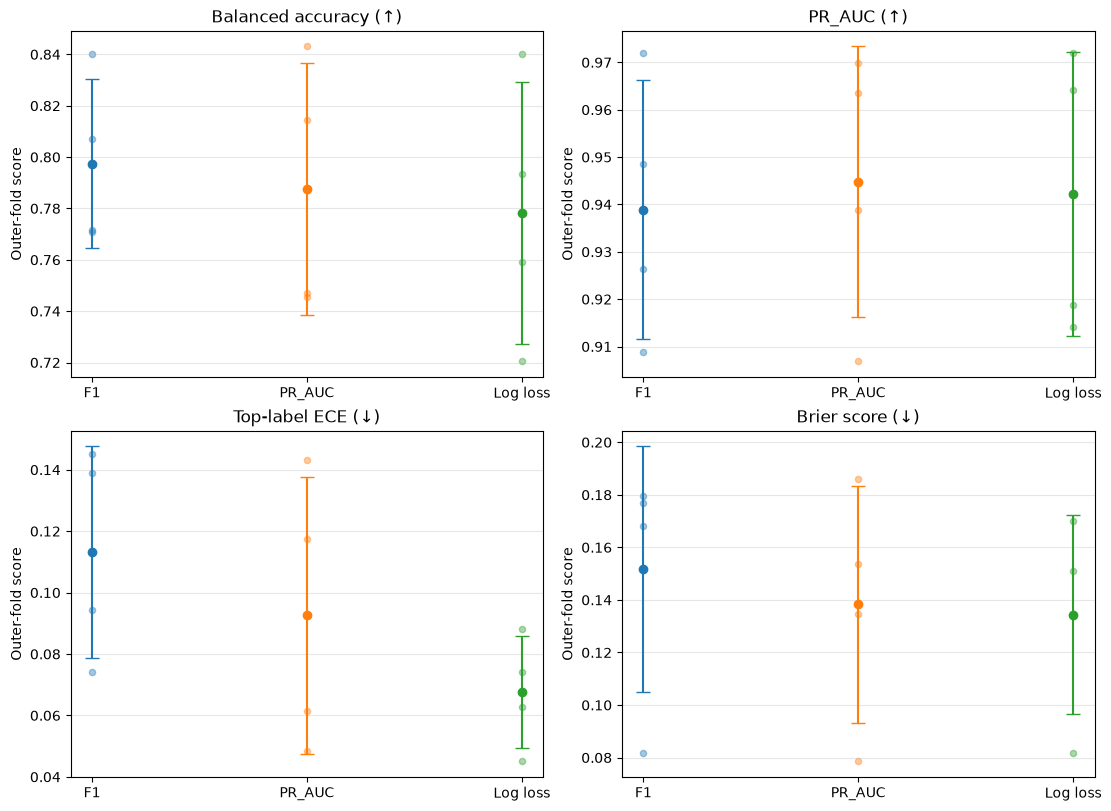

In [ ]:
scorer_colors = dict(zip(scorers, plt.get_cmap("tab10").colors))
metric_rows = []
for (scorer_name, iteration), fold in all_results.groupby(["scorer", "iteration"]):
    y_true = fold["p_np"].to_numpy(dtype=int)
    y_pred = fold["pred_p_np"].to_numpy(dtype=int)
    probabilities = fold[["pred_proba_0", "pred_proba_1"]].to_numpy(dtype=float)

    # Top-label ECE: 10 equal-width confidence bins spanning [0, 1].
    top_labels = probabilities.argmax(axis=1)
    confidence = probabilities.max(axis=1)
    correct = (top_labels == y_true).astype(float)
    bin_ids = np.minimum((confidence * 10).astype(int), 9)

    ece = 0.0
    for bin_id in range(10):
        mask = bin_ids == bin_id
        if mask.any():
            ece += mask.mean() * abs(correct[mask].mean() - confidence[mask].mean())

    metric_rows.append(
        {
            "scorer": scorer_name,
            "iteration": iteration,
            "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
            "PR_AUC": pr_auc(y_true, probabilities[:, 1]),
            "Top-label ECE": ece,
            "Brier score": brier_score_loss(y_true, probabilities[:, 1]),
        }
    )

outer_fold_metrics = pd.DataFrame(metric_rows)
metric_columns = ["Balanced accuracy", "PR_AUC", "Top-label ECE", "Brier score"]
metric_summary = outer_fold_metrics.groupby("scorer")[metric_columns].agg(["mean", "std"]).reindex(scorers.keys())

display(outer_fold_metrics, metric_summary)  # noqa: F821

fig, axes = plt.subplots(2, 2, figsize=(11, 8), constrained_layout=True)
for ax, metric in zip(axes.flat, metric_columns):
    summary = metric_summary[metric]
    positions = np.arange(len(summary))
    for position, scorer_name in enumerate(summary.index):
        ax.errorbar(
            position,
            summary.loc[scorer_name, "mean"],
            yerr=summary.loc[scorer_name, "std"],
            fmt="o",
            capsize=5,
            color=scorer_colors[scorer_name],
            label=f"{scorer_name} mean ± SD",
        )
    for position, scorer_name in enumerate(summary.index):
        fold_values = outer_fold_metrics.loc[outer_fold_metrics["scorer"] == scorer_name, metric]
        ax.scatter(
            np.full(len(fold_values), position),
            fold_values,
            alpha=0.4,
            s=20,
            color=scorer_colors[scorer_name],
        )
    direction = "↑" if metric in metric_columns[:2] else "↓"
    ax.set_title(f"{metric} ({direction})")
    ax.set_xticks(positions, summary.index)
    ax.set_ylabel("Outer-fold score")
    ax.grid(axis="y", alpha=0.3)

plt.show()

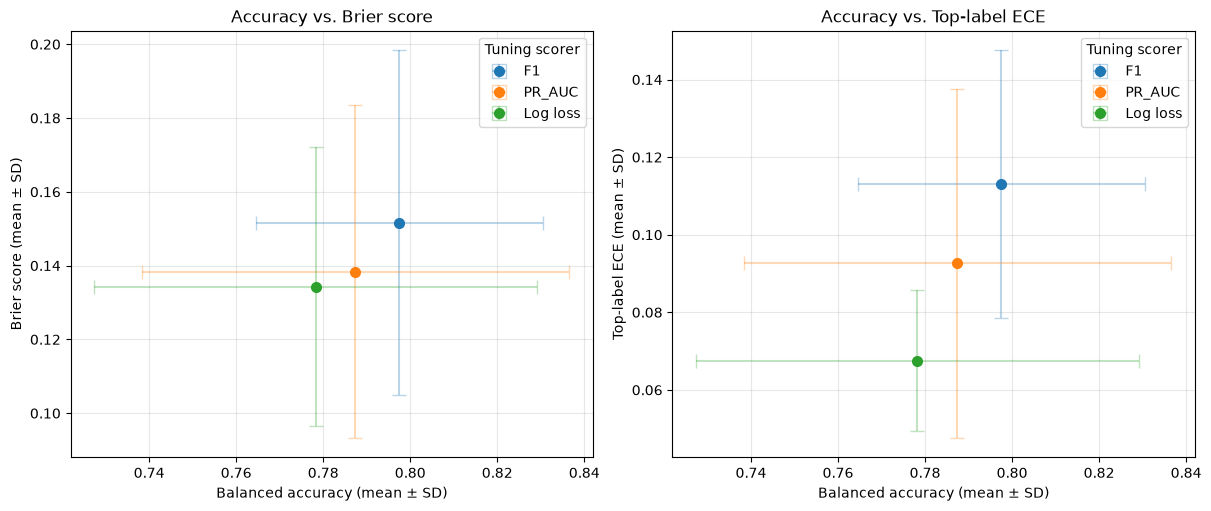

In [152]:
calibration_metrics = ["Brier score", "Top-label ECE"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

for ax, calibration_metric in zip(axes, calibration_metrics):
    for scorer_name in scorers:
        scorer_folds = outer_fold_metrics[outer_fold_metrics["scorer"] == scorer_name]

        line, caps, bars = ax.errorbar(
            scorer_folds["Balanced accuracy"].mean(),
            scorer_folds[calibration_metric].mean(),
            xerr=scorer_folds["Balanced accuracy"].std(),
            yerr=scorer_folds[calibration_metric].std(),
            fmt="o",
            capsize=5,
            markersize=7,
            color=scorer_colors[scorer_name],
            label=scorer_name,
        )

        # set alpha for error bars
        for bar in bars:
            bar.set_alpha(0.3)
        for cap in caps:
            cap.set_alpha(0.3)

    ax.set_xlabel("Balanced accuracy (mean ± SD)")
    ax.set_ylabel(f"{calibration_metric} (mean ± SD)")
    ax.set_title(f"Accuracy vs. {calibration_metric}")
    ax.grid(alpha=0.3)
    ax.legend(title="Tuning scorer")

plt.show()